# Figure 2: transcriptional perturbation over conserved cell states

Reproduces panels a-g of Fig. 2.

Paper: Cheng, Stok Ranen et al., bioRxiv, doi:10.64898/2026.05.14.725081.

- **2a**: core epiblast program, epiblast cells (section: Core program distributions)
- **2b**: divergence scores, epiblast (section: Divergence scores)
- **2c**: core nascent mesoderm program, early nascent mesoderm cells (section: Core program distributions)
- **2d**: divergence scores, early nascent mesoderm (section: Divergence scores)
- **2e**: DKO vs TKO expression changes against host, per lineage (section: DKO vs TKO changes)
- **2f**: methylation-affected genes (Dahlet et al., 2020), observed vs atlas (section: Methylation-affected and imprinted genes)
- **2g**: imprinted genes, observed vs atlas (section: Methylation-affected and imprinted genes)

## Initialization

In [1]:
source("paths.R")
save_figure = F  # TRUE also writes every figure to git_test/ (see show_fig() in paths.R)
source(file.path(repo_dir, "scripts/rna_projection_func.r"))

`RNA_mod` holds, per dataset: single cells (UMIs, metadata), metacell expression (`legc`) and expression projected from the WT atlas (`lpgc`).

Datasets:
- 4N mutants: `WT_4N`, `DNMT_TKO_4N`, `DNMT_DKO_4N`
- chimeras: `DNMT_TKO_KO`, `DNMT_TKO_host`, `DNMT_DKO_KO`, `DNMT_DKO_host`

In [2]:
RNA_mod <- init_RNA_mod(reload_data = FALSE)

Gene sets:
- `gset`: feature genes of the joint query + atlas model, excluding trisomic chromosomes (TKO: chr6, chrX; DKO: chr1, chr14, chrX)
- `weber_genes`: methylation-affected (germline) genes of Dahlet et al., 2020
- imprinted genes
- epiblast and early nascent mesoderm core programs (modules from the TET paper)

In [3]:
gn_sets_list <- load_gene_sets()
str(gn_sets_list)

## Fig. 2a, c: core program distributions

- **2a**: core epiblast program, epiblast cells, 4N mutants and chimeras; atlas dashed
- **2c**: core nascent mesoderm program, early nascent mesoderm cells; atlas dashed

Method:
- Each cell downsampled to 5,000 UMIs; score = log2 of the program's UMI fraction (pseudocount 2e-4).
- Cell states come from projecting each dataset's metacells on the WT atlas.
- Programs are restricted to `gset`, so trisomic genes don't contribute.
- Dashed curves: same score in WT atlas cells (`init_ds_mats` loads the downsampled atlas).

In [4]:
ds_mats_list <- init_ds_mats(re_downsample_atlas_mat = FALSE, re_downsample_mut_matrices = FALSE)

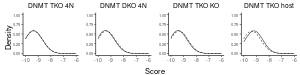

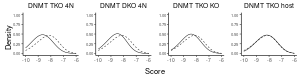

In [5]:
options(repr.plot.width = 10, repr.plot.height = 2.5)
density_figs <- plot_density_plots(RNA_mod = RNA_mod, gn_sets = gn_sets_list, ds_mats = ds_mats_list)

- **2a** (top, `density_figs$epi`): `figs/Fig2/epi_density.png`
- **2c** (bottom, `density_figs$nm`): `figs/Fig2/nm_density.png`

## Fig. 2b, d: divergence scores

- **2b**: embryo-embryo divergence, epiblast, query vs best-matched atlas embryos
- **2d**: same, early nascent mesoderm

Method:
- Per embryo: mean profile of its epiblast (or early nascent mesoderm) cells over feature genes (`data/gc_per/gc_per_embryo_*.h5ad`, from `prep/embryo_profiles.ipynb`).
- Each query embryo is matched, without replacement, to its most correlated atlas embryo; divergence = 1 - r.
- Control: each matched atlas embryo vs its best match among the remaining atlas embryos.
- Test: two-sided Wilcoxon rank-sum, query vs control.
- Jitter uses seed 1; the published panels used unseeded jitter, so point positions differ from them.

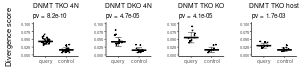

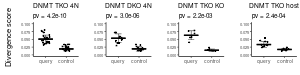

In [6]:
divergence_figs <- plot_divergence_plots(gset = gn_sets_list$gset)

- **2b** (top, `divergence_figs$epi`): `figs/Fig2/epi_divergence.png`
- **2d** (bottom, `divergence_figs$nm`): `figs/Fig2/nm_divergence.png`

## Fig. 2e: DKO vs TKO changes

- **2e**: DKO vs TKO expression change against host, per lineage; methylation-affected genes in blue

`prep_single_cell()` (`scripts/single_cell_func.r`) loads the embryo-matched KO and host pseudo-bulk counts per genotype x lineage (`data/output/mko.RDS`, `mhost.RDS`; recomputed from `data/MC_models/RNA_all.h5ad` only if missing). See `prep/ko_vs_host.ipynb`.

Method:
- Change = log2(1e-5 + KO freq) - log2(1e-5 + host freq), from `sc$mko`, `sc$mhost` (not downsampled).
- Only genes whose change varies by > 2 (max - min) across genotype x lineage columns.
- One panel per lineage (Ecto, EmbMeso, ExMeso, Ery): TKO change (x) vs DKO change (y); Dahlet et al. germline genes in blue; quadrant percentages in the corners.

Notes:
- Pearson r (not drawn): Ecto 0.535, EmbMeso 0.563, ExMeso 0.657, Ery 0.606.

In [7]:
source(file.path(repo_dir, "scripts/single_cell_func.r"))
sc <- prep_single_cell()

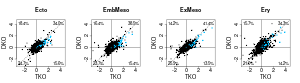

In [8]:
mdlt_full = sc$mdlt_full
f = sc$f_dlt

options(repr.plot.width = 12, repr.plot.height = 3)
gene_col = rep("black", nrow(mdlt_full))
names(gene_col) = rownames(mdlt_full)
gene_col[intersect(names(gene_col),sc$weber_germ)] = "deepskyblue"
weber_highlight = names(which(gene_col == "deepskyblue"))

show_fig("figs/Fig2/cmp_dkotko_dlt.png", w = 3600, h = 1000, res = 300, draw = {
layout(matrix(1:4,nrow=1))
par(mar=c(5,5,6,3))
for(ty in c("Ecto","EmbMeso", "ExMeso", "Ery")) {
    tko_nm = sprintf("DNMT_TKO.%s", ty)
    dko_nm = sprintf("DNMT_DKO.%s", ty)

    x = mdlt_full[f, tko_nm]
    y = mdlt_full[f, dko_nm]

    # quadrant counts
    n_tr = sum(x > 0 & y > 0)
    n_tl = sum(x < 0 & y > 0)
    n_br = sum(x > 0 & y < 0)
    n_bl = sum(x < 0 & y < 0)

    n_tot = length(x)

    p_tr = 100 * n_tr / n_tot
    p_tl = 100 * n_tl / n_tot
    p_br = 100 * n_br / n_tot
    p_bl = 100 * n_bl / n_tot

    plot(
        x, y,
        col = gene_col[f], pch = 19, cex = 0.8,
        cex.lab = 2, cex.axis = 2, cex.main = 2,
        main = ty,
        xlab = "TKO", ylab = "DKO",
        xlim = c(-3, 4.5), ylim = c(-3, 4.5)
    )

    points(x[weber_highlight], y[weber_highlight], col="deepskyblue", pch=19, cex=0.8)
    

    abline(h = 0); abline(v = 0)
    abline(a = 0, b = 1, lty = 2)

    usr = par("usr")  # c(x1,x2,y1,y2)
    padx = 0.03 * (usr[2] - usr[1])
    pady = 0.03 * (usr[4] - usr[3])

    text(usr[1] + padx, usr[4] - pady, labels = sprintf("%.1f%%", p_tl),
         adj = c(0,1), cex = 1.6)
    text(usr[2] - padx, usr[4] - pady, labels = sprintf("%.1f%%", p_tr),
         adj = c(1,1), cex = 1.6)
    text(usr[1] + padx, usr[3] + pady, labels = sprintf("%.1f%%", p_bl),
         adj = c(0,0), cex = 1.6)
    text(usr[2] - padx, usr[3] + pady, labels = sprintf("%.1f%%", p_br),
         adj = c(1,0), cex = 1.6)

}
})

**2e**: `figs/Fig2/cmp_dkotko_dlt.png`.

## Fig. 2f, g: methylation-affected and imprinted genes

- **2f**: methylation-affected genes (Dahlet et al., 2020), mutants vs WT atlas
- **2g**: imprinted genes, mutants vs WT atlas

Method (MCProj gives each query metacell's expected expression from its atlas projection):
- **2f**: median metacell expression of the germline genes, observed (blue) vs projected (grey), per dataset.
- **2g**: median log2 observed/projected of imprinted genes; Dnmt3a and Dnmt3b as controls.

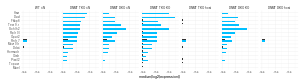

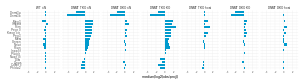

In [9]:
facets <- c("WT 4N", "DNMT TKO 4N", "DNMT DKO 4N", "DNMT TKO KO", "DNMT TKO host", "DNMT DKO KO", "DNMT DKO host")

options(repr.plot.width = 22, repr.plot.height = 6)
p_weber <- plot_obs_vs_proj_barplot(gn_sets_list$weber_genes, facets)
show_fig("./figs/Fig2/weber_genes.pdf", p_weber, width = 22, height = 6)

p_imprinted <- plot_diff_barplot(gn_sets_list$imprinted_genes, facets)
show_fig("./figs/Fig2/imprinted_genes.pdf", p_imprinted, width = 22, height = 6)

- **2f** (top, `p_weber`): `figs/Fig2/weber_genes.pdf`
- **2g** (bottom, `p_imprinted`): `figs/Fig2/imprinted_genes.pdf`